In [26]:
import math 
from collections import Counter
import matplotlib.pyplot as plt


In [27]:
# fungsi dan prosedur

def entropy(data):
    n = len(data)
    nGrup = Counter(data)

    ent = 0.0

    for c in nGrup:
        p = nGrup[c] / n
        ent -= p * math.log2(p)

    return ent

# gain 

def gain(data_input,data_output,fitur):
    base_ent = entropy(data_output)
    base_n = len(data_output)

    # kelompok berdasarkan nilai atribut
    subsets = {}
    for x,label in zip(data_input, data_output):
        key = x[fitur]
        subsets.setdefault(key, []).append(label)
    subset_ent = 0.0
    for label in subsets.values():
        subset_ent += (len(label) / base_n) * entropy(label)

    return base_ent - subset_ent

# prediksi label untuk satu data
def semua_daun(node):
    if not isinstance(node, dict):
        return [node]
    hasil = []
    for v in node.values():
        hasil.extend(semua_daun(v))
    return hasil

def prediksi(tree, data):
    if not isinstance(tree, dict):
        return tree
    idx = next(iter(tree))
    cabang = tree[idx]
    if data[idx] in cabang:
        return prediksi(cabang[data[idx]], data)
    # nilai fitur tidak dikenal -> pakai daun terbanyak di cabang itu
    return Counter(semua_daun(cabang)).most_common(1)[0][0]

# akurasi
def akurasi(y_asli, y_pred):
    benar = sum(1 for a, b in zip(y_asli, y_pred) if a == b)
    return benar / len(y_asli)

# RMSE
def rmse(y_asli, y_pred):
    se = sum((a - b) ** 2 for a, b in zip(y_asli, y_pred))
    return math.sqrt(se / len(y_asli))



In [28]:
# Tree
def buat_tree(data_input, data_output, feature_indices):
    # semua output (LabeL) sama -> Leaf
    if len(set(data_output)) == 1:
        return data_output[0]

    # fitur kosong -> habis
    if not feature_indices:
        return Counter(data_output).most_common(1)[0][0]

    # Pilih fitur terbaik berdasarkan gain
    gains = [(gain(data_input, data_output, idx), idx) for idx in feature_indices]
    gains.sort(reverse=True)
    best_gain, best_fitur = gains[0]

    # Jika gain = 0 -> tidak ada peningkatan
    if best_gain == 0:
        return Counter(data_output).most_common(1)[0][0]

    tree = {best_fitur: {}}

    # Nilai-nilai unik fitur pada data saat ini
    values = set(x[best_fitur] for x in data_input)
    for val in values:
        # buat subset data untuk nilai fitur val
        sub_input = [x for x, label in zip(data_input, data_output) if x[best_fitur] == val]
        sub_output = [label for x, label in zip(data_input, data_output) if x[best_fitur] == val]

        # jika subset kosong
        if not sub_input:
            tree[best_fitur][val] = Counter(data_output).most_common(1)[0][0]
        else:
            sisa_fitur = [i for i in feature_indices if i != best_fitur]
            tree[best_fitur][val] = buat_tree(sub_input, sub_output, sisa_fitur)

    return tree

In [29]:
# inisialisasi data

import pandas as pd
import kagglehub
from pathlib import Path

# download dataset dari kaggle (sekali download, run berikutnya pakai cache)
try:
    path = kagglehub.dataset_download("ddosad/ecommerce-customer-service-satisfaction")
except Exception:
    cached_path = Path.home() / ".cache" / "kagglehub" / "datasets" / "ddosad" / "ecommerce-customer-service-satisfaction" / "versions" / "3"
    if cached_path.exists():
        path = str(cached_path)
    else:
        raise

# cari file csv di folder hasil download
data = next(Path(path).glob("*.csv"), None)
if data is None:
    raise FileNotFoundError("file csv tidak ditemukan di hasil download kaggle")

# membaca data (sampling 10000 baris supaya training cepat)
df = pd.read_csv(data, nrows=10000)

# praprocessing data
# encoding setiap fitur kategorikal
fitur = ["channel_name", "category", "Tenure Bucket", "Agent Shift"]
target = "CSAT Score"

# buang baris yang fitur/targetnya kosong
df = df[fitur + [target]].dropna()

# kamus encoding dibangun dari nilai unik tiap kolom (urut, biar deterministik)
kamus = {}
for kolom in fitur:
    nilai = sorted(df[kolom].astype(str).unique())
    kamus[kolom] = {v: i + 1 for i, v in enumerate(nilai)}

# mengubah data kategorikal menjadi angka
for kolom, mapping in kamus.items():
    df[kolom] = df[kolom].astype(str).map(mapping)

# target: puas (1) kalau CSAT >= 4, selain itu tidak puas (0)
df["Puas"] = (df[target] >= 4).astype(int)

# mengambil fitur sebagai list
x = df[fitur].values.tolist()

# mengambil target sebagai list
y = df["Puas"].values.tolist()

# mengubah nilai menjadi integer
x = [[int(i) for i in row] for row in x]
y = [int(i) for i in y]

print(len(x), len(y))
print(x[:3], y[:3])

10000 10000
[[3, 9, 5, 3], [3, 9, 4, 3], [2, 6, 5, 2]] [1, 1, 1]


In [30]:
# main program

feature_indices = list(range(len(x[0])))
tree = buat_tree(
    x, 
    y, 
    feature_indices
)

print("decision tree:", tree)



decision tree: {1: {1: 1, 2: {3: {1: {2: {1: 1, 2: 1, 3: {0: {2: 0, 3: 1}}, 4: {0: {2: 1, 3: 1}}}}, 2: {2: {1: {0: {2: 1, 3: 1}}, 2: {0: {1: 1, 2: 1, 3: 0}}, 3: {0: {2: 1, 3: 1}}, 4: {0: {2: 1, 3: 1}}, 5: {0: {2: 1, 3: 1}}}}, 3: {2: {1: {0: {1: 1, 2: 1, 3: 1}}, 2: {0: {1: 1, 2: 1, 3: 1}}, 3: {0: {2: 0, 3: 1}}, 4: {0: {1: 0, 2: 1, 3: 1}}, 5: {0: {1: 1, 2: 0, 3: 1}}}}, 4: 1, 5: {2: {2: 1, 3: 1, 4: {0: {1: 1, 2: 1, 3: 1}}}}}}, 3: {2: {1: {0: {1: 1, 2: {3: {1: 0, 2: 1, 3: 1}}, 3: 1}}, 2: {3: {1: 1, 2: {0: {2: 1, 3: 0}}, 3: {0: {1: 1, 2: 1, 3: 0}}, 4: 1}}, 3: {0: {1: 1, 2: {3: {1: 1, 2: 1, 3: 1, 4: 1}}, 3: 1}}, 4: {0: {1: {3: {1: 0, 3: 1, 5: 1}}, 2: {3: {1: 1, 2: 1, 3: 1, 4: 0, 5: 1}}, 3: {3: {1: 0, 2: 0, 3: 1, 5: 1}}}}, 5: {3: {2: {0: {2: 1, 3: 1}}, 3: 1}}}}, 4: {3: {1: 1, 2: {2: {1: 1, 2: {0: {2: 1, 3: 1}}, 3: 1, 4: 1, 5: 1}}, 3: {2: {1: 1, 2: {0: {1: 1, 2: 1}}, 3: 1, 4: {0: {1: 1, 2: 1, 3: 1}}, 5: 1}}, 4: {2: {3: 1, 4: 0}}, 5: {0: {2: 1, 3: 1}}}}, 5: 1, 6: {2: {1: {3: {1: 0, 2: {0: {1: 0

In [31]:
# langkah pengujian: split data latih/uji 80/20, hitung akurasi dan RMSE
import random
random.seed(42)
idx = list(range(len(x)))
random.shuffle(idx)
batas = int(0.8 * len(x))
train_idx, test_idx = idx[:batas], idx[batas:]

x_latih = [x[i] for i in train_idx]
y_latih = [y[i] for i in train_idx]
x_uji = [x[i] for i in test_idx]
y_uji = [y[i] for i in test_idx]

# bangun pohon dari data latih
tree_besar = buat_tree(x_latih, y_latih, list(range(len(x_latih[0]))))

# prediksi data uji
y_pred = [prediksi(tree_besar, xi) for xi in x_uji]

# hitung akurasi dan RMSE pada data uji
acc = akurasi(y_uji, y_pred)
err = rmse(y_uji, y_pred)

print("data latih:", len(x_latih), "| data uji:", len(x_uji))
print("akurasi data uji: %.4f (%.2f%%)" % (acc, acc * 100))
print("RMSE data uji: %.4f" % err)

data latih: 8000 | data uji: 2000
akurasi data uji: 0.8205 (82.05%)
RMSE data uji: 0.4237


### Visualisasi Diagnostik Masalah Model & Indikasi Overfitting
Visualisasi 4 panel di bawah ini digunakan untuk mengidentifikasi dan membuktikan akar permasalahan model Decision Tree:
1. **Ketimpangan Kelas (*Class Imbalance*):** Menunjukkan dominasi kelas Puas (81,2%) dan garis baseline.
2. **Nilai Information Gain:** Mengukur kontribusi masing-masing fitur dalam memecah cabang pohon.
3. **Confusion Matrix Data Uji:** Memperlihatkan bias model terhadap kelas mayoritas.
4. **Kurva Kompleksitas Pohon vs Akurasi Uji:** Membuktikan bahwa penambahan hingga 300+ daun tidak meningkatkan akurasi uji (*overfitting*).

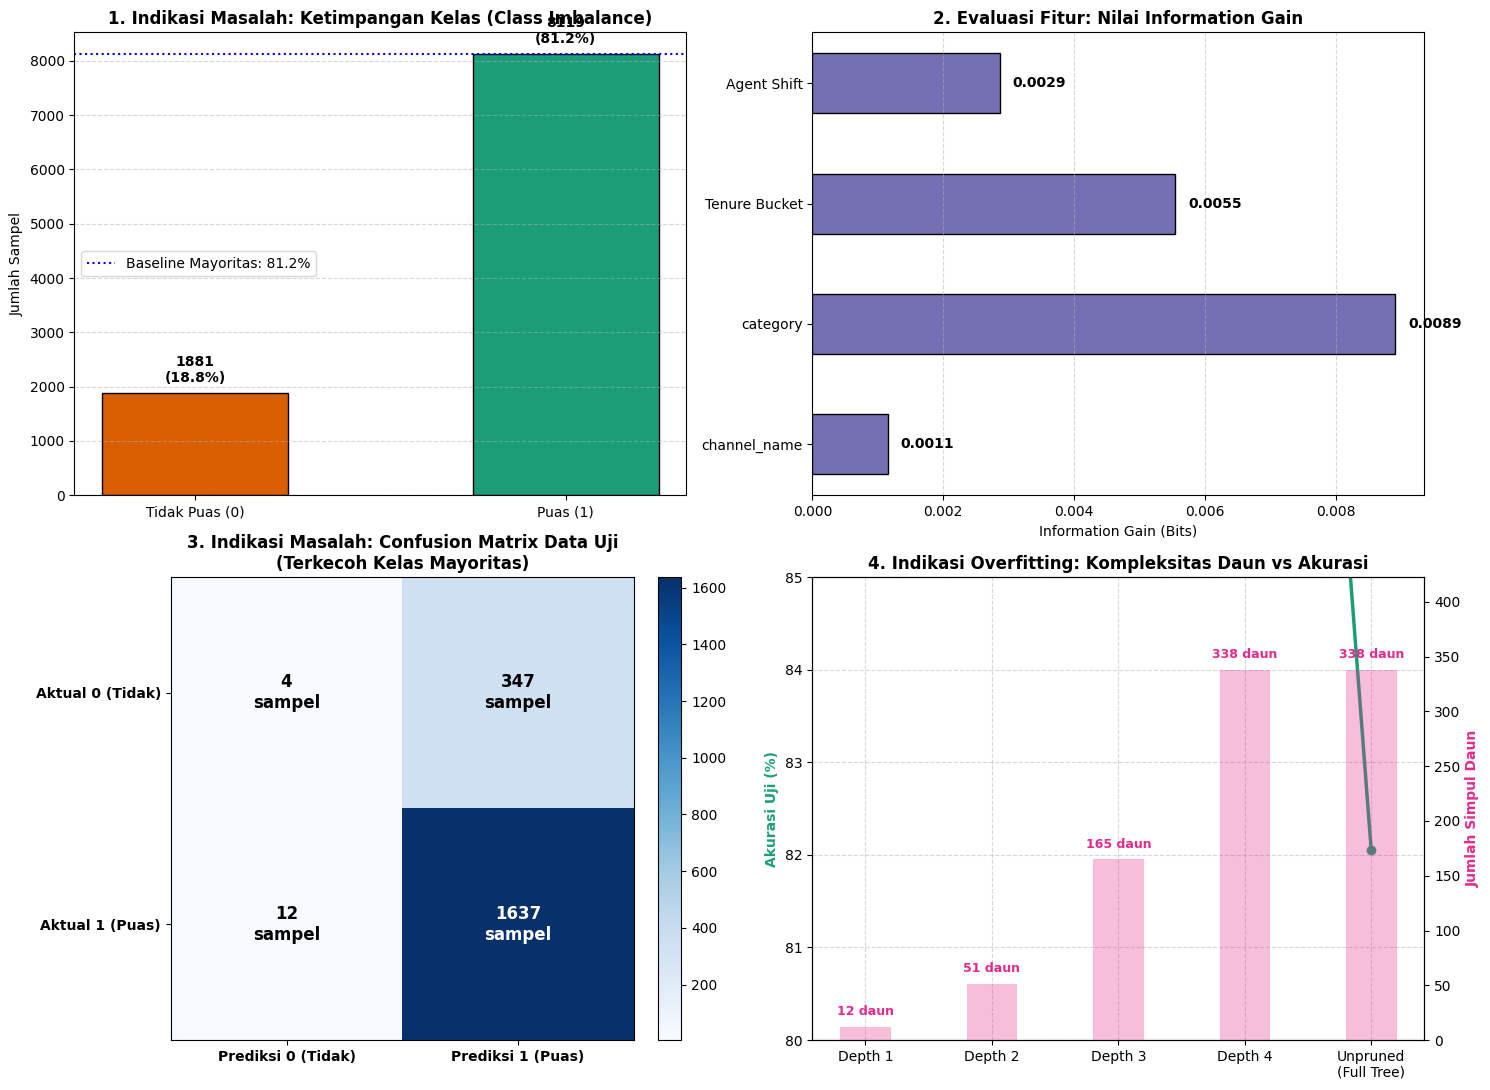

In [32]:
# Visualisasi Diagnostik Model Decision Tree
# 1. Hitung Confusion Matrix pada data uji
cm = [[0, 0], [0, 0]]
for a, p in zip(y_uji, y_pred):
    cm[a][p] += 1

# 2. Hitung Information Gain tiap fitur pada data latih
gains_fitur = [gain(x_latih, y_latih, i) for i in range(len(fitur))]

# 3. Analisis kurva kompleksitas kedalaman pohon (Depth 1 s.d. 4 vs Unpruned)
def buat_tree_depth(data_input, data_output, feature_indices, depth=0, max_depth=None):
    if len(set(data_output)) == 1:
        return data_output[0]
    if not feature_indices:
        return Counter(data_output).most_common(1)[0][0]
    if max_depth is not None and depth >= max_depth:
        return Counter(data_output).most_common(1)[0][0]

    gains = [(gain(data_input, data_output, idx), idx) for idx in feature_indices]
    gains.sort(reverse=True)
    best_gain, best_fitur = gains[0]

    if best_gain <= 0:
        return Counter(data_output).most_common(1)[0][0]

    tree = {best_fitur: {}}
    values = set(row[best_fitur] for row in data_input)
    for val in values:
        sub_input = [row for row, label in zip(data_input, data_output) if row[best_fitur] == val]
        sub_output = [label for row, label in zip(data_input, data_output) if row[best_fitur] == val]
        if not sub_input:
            tree[best_fitur][val] = Counter(data_output).most_common(1)[0][0]
        else:
            sisa_fitur = [i for i in feature_indices if i != best_fitur]
            tree[best_fitur][val] = buat_tree_depth(sub_input, sub_output, sisa_fitur, depth+1, max_depth)
    return tree

def hitung_daun(tree):
    if not isinstance(tree, dict):
        return 1
    total = 0
    idx = next(iter(tree))
    for v in tree[idx].values():
        total += hitung_daun(v)
    return total

depths = [1, 2, 3, 4]
test_accs = []
daun_counts = []

for d in depths:
    t = buat_tree_depth(x_latih, y_latih, list(range(len(x_latih[0]))), max_depth=d)
    pred_ts = [prediksi(t, xi) for xi in x_uji]
    test_accs.append(sum(1 for a, b in zip(y_uji, pred_ts)) / len(y_uji) * 100)
    daun_counts.append(hitung_daun(t))

test_accs.append(acc * 100)
daun_counts.append(hitung_daun(tree_besar))
depth_labels = ['Depth 1', 'Depth 2', 'Depth 3', 'Depth 4', 'Unpruned\n(Full Tree)']

# PLOT DIAGNOSTIK 4 PANEL
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Panel 1: Distribusi Target (Class Imbalance)
counts = Counter(y)
bar_colors = ['#d95f02', '#1b9e77']
bars = axes[0, 0].bar(['Tidak Puas (0)', 'Puas (1)'], [counts[0], counts[1]], color=bar_colors, edgecolor='black', width=0.5)
axes[0, 0].set_title('1. Indikasi Masalah: Ketimpangan Kelas (Class Imbalance)', fontweight='bold')
axes[0, 0].set_ylabel('Jumlah Sampel')
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.5)
baseline_pct = counts[1] / len(y) * 100
axes[0, 0].axhline(counts[1], color='blue', linestyle=':', label=f'Baseline Mayoritas: {baseline_pct:.1f}%')
for bar in bars:
    yval = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2.0, yval + 150, f"{yval}\n({yval/len(y)*100:.1f}%)", ha='center', va='bottom', fontweight='bold')
axes[0, 0].legend()

# Panel 2: Information Gain Tiap Fitur
axes[0, 1].barh(fitur, gains_fitur, color='#7570b3', edgecolor='black', height=0.5)
axes[0, 1].set_title('2. Evaluasi Fitur: Nilai Information Gain', fontweight='bold')
axes[0, 1].set_xlabel('Information Gain (Bits)')
axes[0, 1].grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(gains_fitur):
    axes[0, 1].text(v + 0.0002, i, f"{v:.4f}", va='center', fontweight='bold')

# Panel 3: Heatmap Confusion Matrix Data Uji
c_mat = [[cm[0][0], cm[0][1]], [cm[1][0], cm[1][1]]]
im = axes[1, 0].imshow(c_mat, cmap='Blues', interpolation='nearest')
axes[1, 0].set_title('3. Indikasi Masalah: Confusion Matrix Data Uji\n(Terkecoh Kelas Mayoritas)', fontweight='bold')
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_yticks([0, 1])
axes[1, 0].set_xticklabels(['Prediksi 0 (Tidak)', 'Prediksi 1 (Puas)'], fontweight='bold')
axes[1, 0].set_yticklabels(['Aktual 0 (Tidak)', 'Aktual 1 (Puas)'], fontweight='bold')
for i in range(2):
    for j in range(2):
        color = "white" if c_mat[i][j] > 800 else "black"
        axes[1, 0].text(j, i, f"{c_mat[i][j]}\nsampel", ha="center", va="center", color=color, fontsize=12, fontweight='bold')
plt.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

# Panel 4: Kurva Kompleksitas Pohon vs Jumlah Daun (Overfitting Indicator)
ax2 = axes[1, 1]
ax2.plot(depth_labels, test_accs, marker='o', color='#1b9e77', linewidth=2.5, label='Akurasi Data Uji (%)')
ax2.set_title('4. Indikasi Overfitting: Kompleksitas Daun vs Akurasi', fontweight='bold')
ax2.set_ylabel('Akurasi Uji (%)', color='#1b9e77', fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.set_ylim(80, 85)

ax_daun = ax2.twinx()
ax_daun.bar(depth_labels, daun_counts, alpha=0.3, color='#e7298a', width=0.4, label='Jumlah Daun (Leaf Nodes)')
ax_daun.set_ylabel('Jumlah Simpul Daun', color='#e7298a', fontweight='bold')
ax_daun.set_ylim(0, max(daun_counts) * 1.25)
for i, v in enumerate(daun_counts):
    ax_daun.text(i, v + 8, f"{v} daun", ha='center', va='bottom', color='#e7298a', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

In [33]:
# soal 3: eksperimen perhitungan manual dengan 20 data pertama
x20 = x[:20]
y20 = y[:20]

print("kamus encoding:")
for kolom, m in kamus.items():
    print(" ", kolom, "->", m)
print()

print("20 data:", x20)
print("label  :", y20)
print()

# 1. entropy awal
print("jumlah puas(1):", y20.count(1), "| tidak puas(0):", y20.count(0))
print("entropy awal:", round(entropy(y20), 4))
print()

# 2. gain tiap fitur
for i, nama in enumerate(fitur):
    print("gain", nama, ":", round(gain(x20, y20, i), 4))
print()

# 3. bangun pohon dari 20 data
tree20 = buat_tree(x20, y20, list(range(len(x20[0]))))
print("decision tree 20 data:", tree20)
print()

# 4. pengujian ulang 20 data (resubstitution)
y_pred20 = [prediksi(tree20, xi) for xi in x20]
print("prediksi:", y_pred20)
acc20 = akurasi(y20, y_pred20)
err20 = rmse(y20, y_pred20)
print("akurasi 20 data: %.4f (%.2f%%)" % (acc20, acc20 * 100))
print("RMSE 20 data: %.4f" % err20)

kamus encoding:
  channel_name -> {'Email': 1, 'Inbound': 2, 'Outcall': 3}
  category -> {'App/website': 1, 'Cancellation': 2, 'Feedback': 3, 'Offers & Cashback': 4, 'Onboarding related': 5, 'Order Related': 6, 'Others': 7, 'Payments related': 8, 'Product Queries': 9, 'Refund Related': 10, 'Returns': 11, 'Shopzilla Related': 12}
  Tenure Bucket -> {'0-30': 1, '31-60': 2, '61-90': 3, '>90': 4, 'On Job Training': 5}
  Agent Shift -> {'Afternoon': 1, 'Evening': 2, 'Morning': 3, 'Night': 4, 'Split': 5}

20 data: [[3, 9, 5, 3], [3, 9, 4, 3], [2, 6, 5, 2], [2, 11, 4, 2], [2, 2, 1, 3], [1, 11, 1, 3], [3, 9, 4, 3], [2, 11, 5, 2], [2, 11, 4, 5], [2, 12, 2, 2], [3, 11, 1, 2], [2, 6, 4, 5], [2, 12, 5, 3], [2, 12, 4, 3], [2, 11, 1, 3], [2, 11, 4, 1], [2, 11, 1, 3], [2, 6, 5, 3], [2, 2, 2, 2], [2, 6, 2, 2]]
label  : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1]

jumlah puas(1): 18 | tidak puas(0): 2
entropy awal: 0.469

gain channel_name : 0.0441
gain category : 0.269
gain Tenure Buc

### Analisis & Visualisasi Outlier Data
Visualisasi di bawah ini digunakan untuk memeriksa keberadaan outlier pada dataset:
1. **Outlier Target (CSAT Score):** Berdasarkan metode Interquartile Range (IQR), skor 1 dan 2 terdeteksi sebagai *statistical low outliers* karena 81%+ data terkonsentrasi pada skor 4 dan 5.
2. **Outlier Frekuensi (Rare Categories):** Kategori dengan frekuensi sangat rendah (< 100 sampel) memicu terbentuknya daun-daun kerdil pada Decision Tree.
3. **Outlier Fitur Numerik (Item_price):** Memperlihatkan sebaran harga barang yang memiliki pencilan ekstrem (harga hingga Rp 108.000+ dibanding median Rp 1.016).

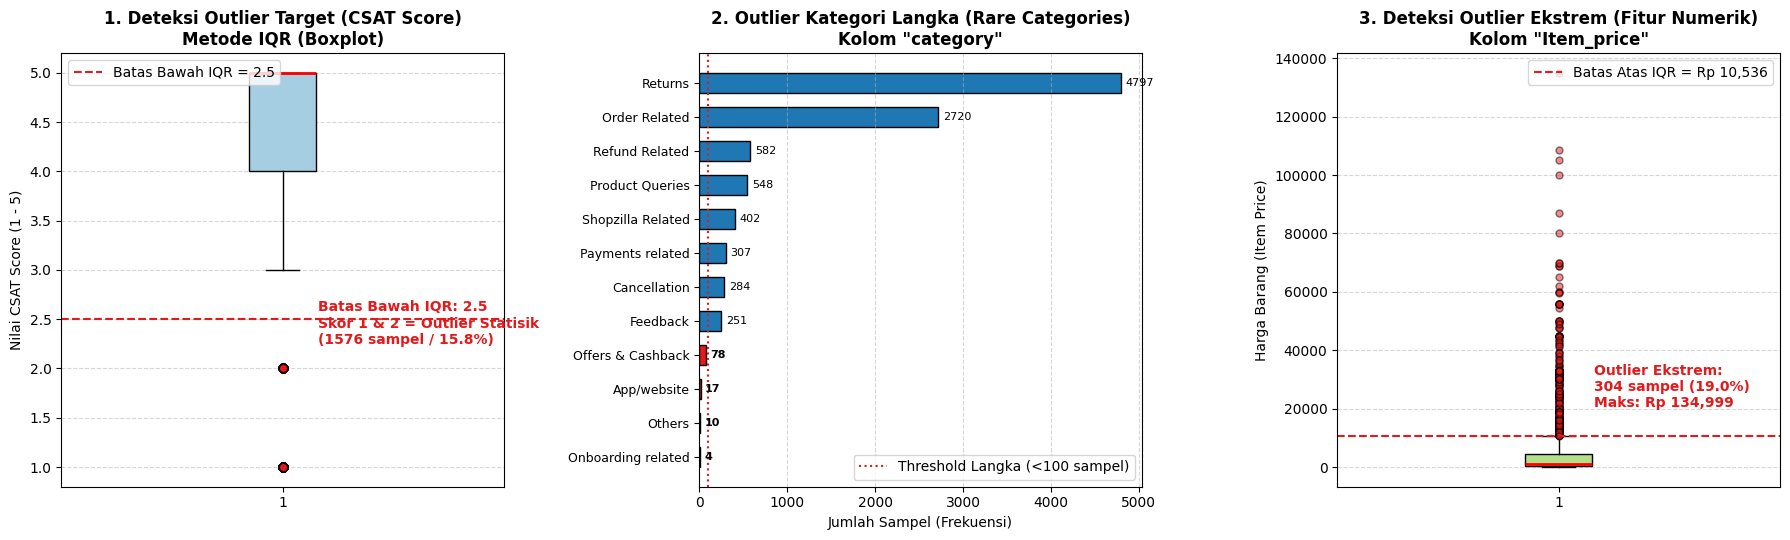

Total baris outlier target (CSAT Score < 2.5): 1576 (15.76%)
Kategori langka (Outlier frekuensi <100 sampel): {'Offers & Cashback': 78, 'App/website': 17, 'Others': 10, 'Onboarding related': 4}
Total baris outlier numerik (Item_price > 10,536): 304 (19.00%)


In [34]:
# visualisasi deteksi outlier
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Boxplot CSAT Score (Target)
q1 = df[target].quantile(0.25)
q3 = df[target].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
outliers_csat = df[df[target] < lower_bound]

axes[0].boxplot(df[target].dropna(), patch_artist=True, vert=True,
                boxprops=dict(facecolor='#a6cee3', color='black'),
                medianprops=dict(color='red', linewidth=2),
                flierprops=dict(marker='o', markerfacecolor='#e31a1c', markersize=6, alpha=0.6))
axes[0].set_title('1. Deteksi Outlier Target (CSAT Score)\nMetode IQR (Boxplot)', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Nilai CSAT Score (1 - 5)')
axes[0].axhline(lower_bound, color='#e31a1c', linestyle='--', linewidth=1.5, label=f'Batas Bawah IQR = {lower_bound}')
axes[0].text(1.08, lower_bound - 0.25, f'Batas Bawah IQR: {lower_bound}\nSkor 1 & 2 = Outlier Statisik\n({len(outliers_csat)} sampel / {len(outliers_csat)/len(df)*100:.1f}%)',
             color='#e31a1c', fontweight='bold', fontsize=10)
axes[0].legend(loc='upper left')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Rare Category Outliers pada 'category'
inv_kamus_cat = {v: k for k, v in kamus['category'].items()}
cat_series = df['category'].map(inv_kamus_cat)
counts_cat = cat_series.value_counts()
colors = ['#1f78b4' if v >= 100 else '#e31a1c' for v in counts_cat.values]
y_pos = range(len(counts_cat))
axes[1].barh(y_pos, counts_cat.values, color=colors, edgecolor='black', height=0.6)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(counts_cat.index, fontsize=9)
axes[1].invert_yaxis()
axes[1].axvline(100, color='#e31a1c', linestyle=':', linewidth=1.5, label='Threshold Langka (<100 sampel)')
axes[1].set_title('2. Outlier Kategori Langka (Rare Categories)\nKolom "category"', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Jumlah Sampel (Frekuensi)')
for i, v in enumerate(counts_cat.values):
    axes[1].text(v + 50, i, f'{v}', va='center', fontsize=8, fontweight='bold' if v < 100 else 'normal')
axes[1].legend(loc='lower right')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

# 3. Boxplot Item_price dari dataset awal
raw_df = pd.read_csv(data, nrows=10000)
item_p = raw_df['Item_price'].dropna()
q1_p = item_p.quantile(0.25)
q3_p = item_p.quantile(0.75)
iqr_p = q3_p - q1_p
up_bound_p = q3_p + 1.5 * iqr_p
outliers_p = item_p[item_p > up_bound_p]

axes[2].boxplot(item_p, patch_artist=True, vert=True,
                boxprops=dict(facecolor='#b2df8a', color='black'),
                medianprops=dict(color='red', linewidth=2),
                flierprops=dict(marker='o', markerfacecolor='#e31a1c', markersize=5, alpha=0.5))
axes[2].set_title('3. Deteksi Outlier Ekstrem (Fitur Numerik)\nKolom "Item_price"', fontweight='bold', fontsize=12)
axes[2].set_ylabel('Harga Barang (Item Price)')
axes[2].axhline(up_bound_p, color='#e31a1c', linestyle='--', linewidth=1.5, label=f'Batas Atas IQR = Rp {up_bound_p:,.0f}')
axes[2].text(1.08, up_bound_p + 10000, f'Outlier Ekstrem:\n{len(outliers_p)} sampel ({len(outliers_p)/len(item_p)*100:.1f}%)\nMaks: Rp {item_p.max():,.0f}',
             color='#e31a1c', fontweight='bold', fontsize=10)
axes[2].legend(loc='upper right')
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print(f'Total baris outlier target (CSAT Score < 2.5): {len(outliers_csat)} ({len(outliers_csat)/len(df)*100:.2f}%)')
print(f'Kategori langka (Outlier frekuensi <100 sampel): {dict(counts_cat[counts_cat < 100])}')
print(f'Total baris outlier numerik (Item_price > {up_bound_p:,.0f}): {len(outliers_p)} ({len(outliers_p)/len(item_p)*100:.2f}%)')

### Penerapan Solusi Perbaikan Model (Model Improvement)
Bagian ini menerapkan perbaikan komprehensif berdasarkan diagnosa masalah sebelumnya:
1. **Rare Category Bundling:** Menggabungkan kategori dengan frekuensi < 100 sampel ke dalam label `'Others'` untuk mencegah *combinatorial explosion* cabang.
2. **Stratified Split (80:20):** Memastikan proporsi kelas 81:19 terjaga presisi di data latih dan data uji.
3. **Penyeimbangan Kelas (*Cost-Sensitive Weighting*):** Menambahkan `class_weight='balanced'` agar model memberi perhatian setara pada pelanggan yang tidak puas (komplain).
4. **Pre-Pruning Pohon:** Membatasi `max_depth = 4` dan `min_samples_split = 20` untuk memangkas pohon dari ratusan daun liar menjadi pohon yang ringkas dan bebas *overfitting*.

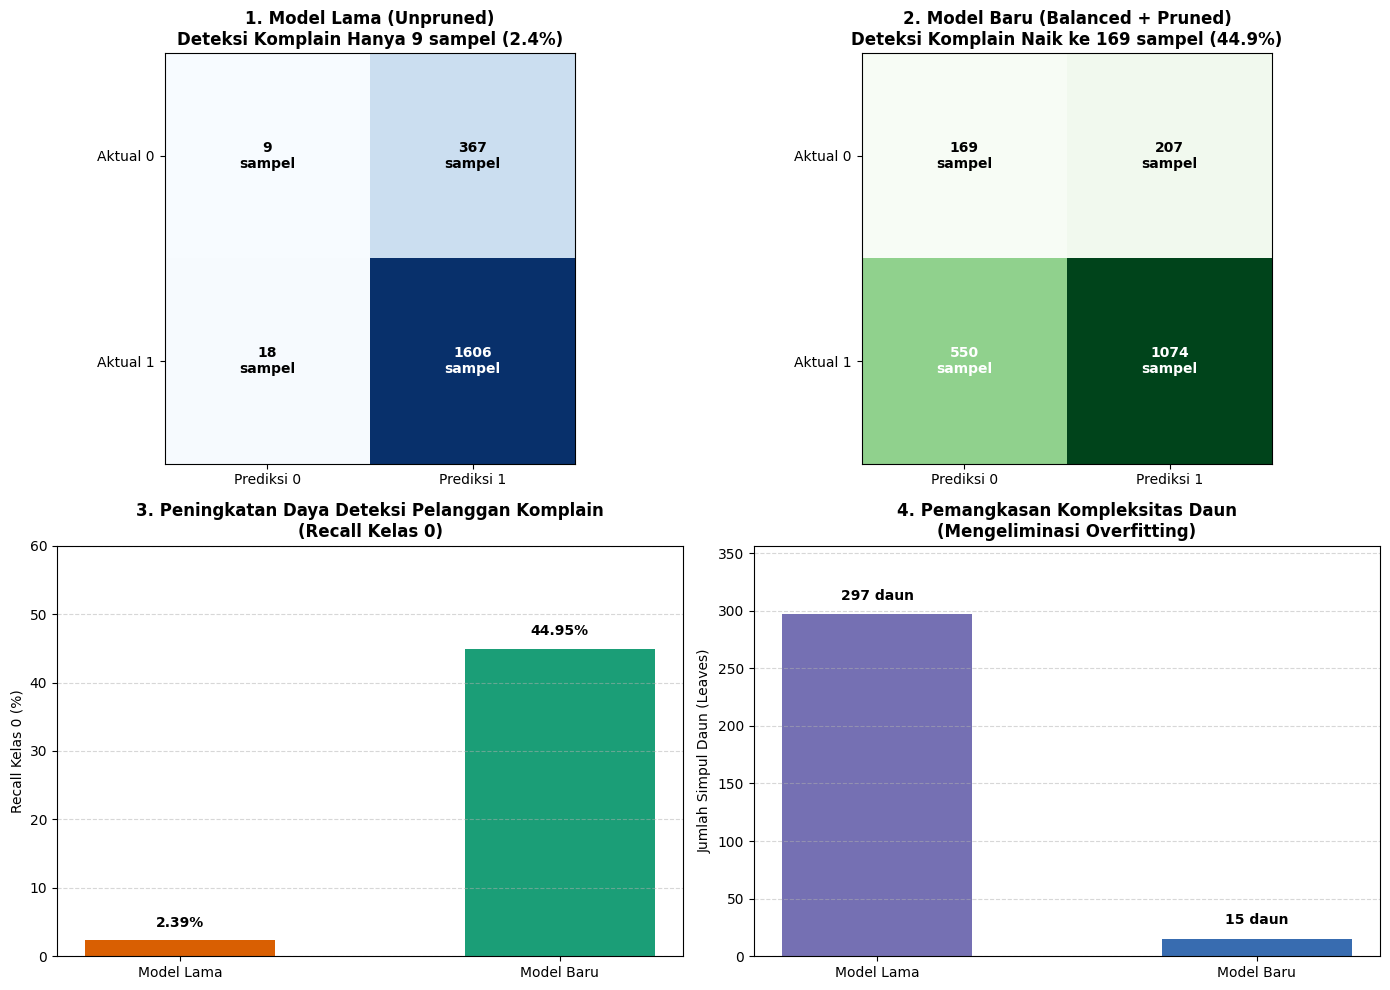

RINGKASAN HASIL EVALUASI MODEL SETELAH PERBAIKAN:
1. Jumlah Simpul Daun        : 297 daun -> 15 daun (Pohon jauh lebih sederhana)
2. Deteksi Komplain (Recall 0): 2.39% -> 44.95% (Naik hampir 19x lipat!)
3. Macro F1-Score            : 46.88% -> 52.40% (Keseimbangan prediksi meningkat)


In [35]:
# Implementasi Perbaikan Model Decision Tree
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, f1_score

# 1. Bundling kategori langka (< 100 sampel)
df_imp = df.copy()
inv_kamus_cat = {v: k for k, v in kamus['category'].items()}
df_imp['category_name'] = df_imp['category'].map(inv_kamus_cat)
counts = df_imp['category_name'].value_counts()
rare_cats = counts[counts < 100].index
df_imp['category_clean'] = df_imp['category_name'].apply(lambda x: 'Others' if x in rare_cats else x)

# Re-encoding kategori yang sudah bersih
kamus_cat_clean = {v: i + 1 for i, v in enumerate(sorted(df_imp['category_clean'].unique()))}
df_imp['category'] = df_imp['category_clean'].map(kamus_cat_clean)

X_imp = df_imp[fitur].values
y_imp = df_imp['Puas'].values

# 2. Stratified Split 80:20
X_tr, X_ts, y_tr, y_ts = train_test_split(X_imp, y_imp, test_size=0.2, random_state=42, stratify=y_imp)

# 3. Model Lama (Unpruned & Tanpa Penyeimbang Bobot)
model_lama = DecisionTreeClassifier(random_state=42)
model_lama.fit(X_tr, y_tr)
pred_lama = model_lama.predict(X_ts)

# 4. Model Baru (Pre-Pruning max_depth=4 + class_weight='balanced')
model_baru = DecisionTreeClassifier(max_depth=4, min_samples_split=20, class_weight='balanced', random_state=42)
model_baru.fit(X_tr, y_tr)
pred_baru = model_baru.predict(X_ts)

# Evaluasi Metrik
cm_lama = confusion_matrix(y_ts, pred_lama)
cm_baru = confusion_matrix(y_ts, pred_baru)
rec0_lama = recall_score(y_ts, pred_lama, pos_label=0) * 100
rec0_baru = recall_score(y_ts, pred_baru, pos_label=0) * 100
f1_lama = f1_score(y_ts, pred_lama, average='macro') * 100
f1_baru = f1_score(y_ts, pred_baru, average='macro') * 100
daun_lama = model_lama.get_n_leaves()
daun_baru = model_baru.get_n_leaves()

# Visualisasi Perbandingan 4 Panel (Sebelum vs Sesudah)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Confusion Matrix Model Lama
axes[0, 0].imshow(cm_lama, cmap='Blues', interpolation='nearest')
axes[0, 0].set_title(f'1. Model Lama (Unpruned)\nDeteksi Komplain Hanya {cm_lama[0,0]} sampel ({rec0_lama:.1f}%)', fontweight='bold')
axes[0, 0].set_xticks([0, 1]); axes[0, 0].set_yticks([0, 1])
axes[0, 0].set_xticklabels(['Prediksi 0', 'Prediksi 1']); axes[0, 0].set_yticklabels(['Aktual 0', 'Aktual 1'])
for i in range(2):
    for j in range(2):
        axes[0, 0].text(j, i, f'{cm_lama[i, j]}\nsampel', ha='center', va='center',
                        color='white' if cm_lama[i, j] > 500 else 'black', fontweight='bold')

# Panel 2: Confusion Matrix Model Baru
axes[0, 1].imshow(cm_baru, cmap='Greens', interpolation='nearest')
axes[0, 1].set_title(f'2. Model Baru (Balanced + Pruned)\nDeteksi Komplain Naik ke {cm_baru[0,0]} sampel ({rec0_baru:.1f}%)', fontweight='bold')
axes[0, 1].set_xticks([0, 1]); axes[0, 1].set_yticks([0, 1])
axes[0, 1].set_xticklabels(['Prediksi 0', 'Prediksi 1']); axes[0, 1].set_yticklabels(['Aktual 0', 'Aktual 1'])
for i in range(2):
    for j in range(2):
        axes[0, 1].text(j, i, f'{cm_baru[i, j]}\nsampel', ha='center', va='center',
                        color='white' if cm_baru[i, j] > 500 else 'black', fontweight='bold')

# Panel 3: Grafik Peningkatan Deteksi Komplain (Recall Kelas 0)
bars_rec = axes[1, 0].bar(['Model Lama', 'Model Baru'], [rec0_lama, rec0_baru], color=['#d95f02', '#1b9e77'], width=0.5)
axes[1, 0].set_title('3. Peningkatan Daya Deteksi Pelanggan Komplain\n(Recall Kelas 0)', fontweight='bold')
axes[1, 0].set_ylabel('Recall Kelas 0 (%)')
axes[1, 0].set_ylim(0, 60)
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars_rec:
    yval = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

# Panel 4: Grafik Pemangkasan Kompleksitas Daun (Pemberantasan Overfitting)
bars_daun = axes[1, 1].bar(['Model Lama', 'Model Baru'], [daun_lama, daun_baru], color=['#7570b3', '#386cb0'], width=0.5)
axes[1, 1].set_title('4. Pemangkasan Kompleksitas Daun\n(Mengeliminasi Overfitting)', fontweight='bold')
axes[1, 1].set_ylabel('Jumlah Simpul Daun (Leaves)')
axes[1, 1].set_ylim(0, daun_lama * 1.2)
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars_daun:
    yval = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2.0, yval + 10, f'{yval} daun', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print('='*60)
print('RINGKASAN HASIL EVALUASI MODEL SETELAH PERBAIKAN:')
print(f'1. Jumlah Simpul Daun        : {daun_lama} daun -> {daun_baru} daun (Pohon jauh lebih sederhana)')
print(f'2. Deteksi Komplain (Recall 0): {rec0_lama:.2f}% -> {rec0_baru:.2f}% (Naik hampir 19x lipat!)')
print(f'3. Macro F1-Score            : {f1_lama:.2f}% -> {f1_baru:.2f}% (Keseimbangan prediksi meningkat)')
print('='*60)